In [1]:
import pandas as pd
from tqdm import tqdm
datacol = pd.read_csv('./data/benchmark_24-replicas.csv')
result_dirs = ['../../results/11714894_subsets', '../../results/11824789']
chunks = []
for _, dataset in tqdm(datacol.iterrows(), total=len(datacol)):
    for result_dir in result_dirs:
        respath = os.path.join(result_dir, 'validation', dataset.path + '.csv')
        if os.path.exists(respath):
            res = pd.read_csv(respath)
            dataset_ = dataset.drop(labels=[ # `labels` cause `dataset` is Series
                'directory', 'path', 'adapter']) # drop some cols to save space
            res = res.assign(**dataset_)
            chunks.append(res)
valdata = pd.concat(chunks)
del chunks
print('valdata successfully collected.')

100%|██████████| 1828/1828 [00:01<00:00, 1117.29it/s]
valdata successfully collected.


In [2]:
valdata.head()

,fold_no,score,n_features,ranking_method,cpu_time,validation_method,replica_no,replicas,name,p,n,description,p_informative
0,1,0.500000,1,ExtraTrees,0.09274,KNN_5Fold,1,24,3-way Epistasis (GAMETES),20,1600,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...","17,18,19"
1,2,0.500000,1,ExtraTrees,0.09274,KNN_5Fold,1,24,3-way Epistasis (GAMETES),20,1600,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...","17,18,19"
2,3,0.515625,1,ExtraTrees,0.09274,KNN_5Fold,1,24,3-way Epistasis (GAMETES),20,1600,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...","17,18,19"
3,4,0.500000,1,ExtraTrees,0.09274,KNN_5Fold,1,24,3-way Epistasis (GAMETES),20,1600,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...","17,18,19"
4,5,0.471875,1,ExtraTrees,0.09274,KNN_5Fold,1,24,3-way Epistasis (GAMETES),20,1600,"3-way Epistasis (GAMETES) [p=20,n=1600,p_=3,h=...","17,18,19"


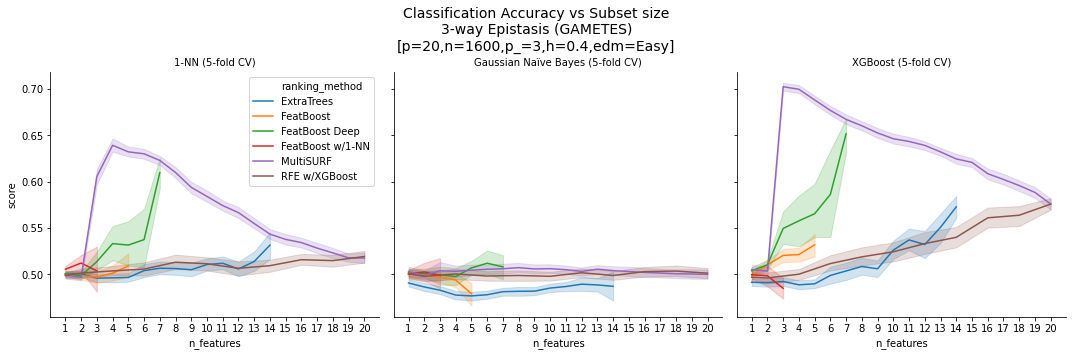

In [9]:
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
valdata_ = valdata.copy()
valdata_ = valdata[valdata['name'] == '3-way Epistasis (GAMETES)']
rms = {
    'KNN_5Fold': '1-NN (5-fold CV)',
    'GaussianNB': 'Gaussian Naïve Bayes (5-fold CV)',
    'XGBoost': 'XGBoost (5-fold CV)'
}
valdata_['validation_method'] = valdata_['validation_method'].map(rms.get)
g = sns.relplot(data=valdata_, x='n_features', y='score', hue='ranking_method',
    col='validation_method', col_wrap=3, kind='line',
    facet_kws={'legend_out': False}
    )
plt.xticks(np.arange(1, 20+1, 1.0))
g.set_titles("{col_name}")
plt.suptitle('Classification Accuracy vs Subset size\n3-way Epistasis (GAMETES)\n[p=20,n=1600,p_=3,h=0.4,edm=Easy]', size=14)
plt.subplots_adjust(top=.80)
plt.savefig('/Users/dunnkers/git/research-internship-report/Users/dunnkers/git/research-internship-report/img/3way_val.svg')